<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/M4_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group 11 Assignment 2 - Milestone 4: Baseline Modeling, Evaluation & Data Generation Strategy

## Bike Share Station Demand for Growth Planning

### Members
- Karen Junsay
- Aditi Singh
- Matthew Jones
- John Aaron

## Part 1: Experimental Design & Data Preparation

### 1.1 Modeling Objective

**Problem Formulation:** Can we predict the hourly departures and arrivals at bike stations and classify whether the demand for a station is Low, Medium, or High, so that Bike Share Toronto can plan where to add new docks or stations?

**Target Variables:**

1. **Regression:** Departures per station per hour, Arrivals per station per hour during the peak months (May to October).
- For each month, a station is considered as open/operating if there is at least 1 trip starting at that station.
- For open/operating stations, hours with zero trips (ex. typical of night time hours) are included in the model.
- In Milestone 3, we set the following flags in the cleaned data to mark valid or invalid trips:
    - `flag_short`: Trip duration is under 60 seconds
    - `flag_long`: Trip duration is over 6 hours
    - `flag_no_end`: The trip has no `End_Station_Id`
    - `is_valid`: True when none of the flags is set, False if at least one is set
- (a) Departures - Valid trips (rows) have no `flag_short` or `flag_long` set. A missing end station doesn't matter.
- (b) Arrivals - Valid trips (rows) have none of the flags (`flag_short`, `flag_long`, `flag_no_end`) set.
    - Note: We said in Milestone 3 that we would no longer include Arrivals as a target variable due to the missing `End_Station_Id`s. However, after discussion, we have decided that the small percentage of missing `End_Station_Id`s should not affect the model too much, and this target variable is relevant in determining how busy a station is.

2. **Classification:** Predict the demand of stations during May-October 2025 as Low, Medium, or High, based on the training data from the same months in 2023 and 2024.
- One row is one station in one month. A station-month exists if the station had at least 1 valid departure in that month.
- Demand rate for a station is calculated by the average valid departures per operating day for this version.
    - An operating day is all the days in an operating month (if there is at least 1 valid departure in that month, all days in that month will be considered operating days). This is the same rule as we used for the Regression task, and we keep it here for consistency.
    - Days with no trips in an operating month will have a zero demand.
    - Valid departures use the same `is_valid` flag as in Milestone 3. Arrivals are not included in this rate.
    - Note: There are changes from Milestone 3, namely changing the definition to use operating days instead of the active days, because using active days only hides low-demand stations that may have few active days.
- The thresholds for the classification are the following:
    - Low: Less than 9.03
    - Medium: In between 9.03 - 35.81
    - High: Greater than 35.81
- Stations that first appear in 2025 have no 2023 to 2024 rate and are not in the classification data. They are used only in the business check that compares 2024 High stations with the new 2025 stations.
    

**Features:**

Each ML task has a different set of features.

1. **Regression**
- One row per station per hour
- (a) Features from date/timestamp:

     - `hour_of_day` - categorical values: hr_0-hr_23, rush hour will have different behaviour
     - `day_of_week` - categorical values: Monday(0)-Sunday(6), riding patterns are different on weekdays and weekends
     - `weekend_or_holiday` - flag (1 if weekend or holiday, 0 otherwise)
     - `year` - numerical values: 2023, 2024, 2025
     - `month` - categorical values: May-Oct

- (b) Features from weather

    - `prec_mm_hr` - numerical value, precipitation/rain in that hour
    - `mean_temp_c_hr` - numerical value, temperature in that hour
    - `prec_mm_prev_hr` - numerical value, precipitation/rain in the previous hour (since people check weather before deciding to ride)

- (c) Features from station:

    - `station_id` - categorical
    - `new_station` - flag (1 if first month that the station is seen, 0 otherwise). We are doing regression on May to October months only, but we have data from January 2023. We will check for the first occurrence of a station since the very beginning of our data (January 2023) in order to set this flag. (Note that this information is in Milestone 3, since we cleaned the data using the entire dataset)


2. **Classification**

- One row per station per month (May to October)
- (a) Features from month's activity:
     - `monthly_volume` - numerical value, valid departures from the station in that month.
      - `was_flagged_new` - flag (1 if that month is the first month the station appears in the data, 0 otherwise). `is_new_start_station` flag from Milestone 3 on monthly level.

- (b) Features from station history (Milestone 3 station months)
    - `first_year` - numerical value, the year the station first appears in the data.
    - `first_month` - numerical value, the month the station first appears in the data.

### 1.2 Evaluation Criteria aligned with the Problem

Our training-validation-test split has been changed since Milestone 3:
- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

We will score each model using the Validation set to help choose the best settings (hyperparameter tuning) and models. Once a model and/or its hyperparameter settings have been chosen, we will rerun the training on the Training+Validation set and evaluate this final model on the Test set once at the end.

1. **Regression** (departures per hour, arrivals per hour)
- Performance metrics: MAE, RMSE for departures and arrivals separately, since they are separate models.
- Baseline to compare against: average departures/arrivals for the same station, hour of day, and day of week in the training months.
- Success criteria: MAE on Test set should be lower than the baseline for both departures and arrivals.

2. **Classification**
- Performance metrics: Accuracy, precision, recall, f1 score and ROC curves.
- Baseline to compare against: Thresholds for low, medium and high use stations. Compare by looking at data and finding good thresholds to use.
- Success criteria: If our classifiers can reduce false positive so the planner adds bikes and stations only where they're needed.

3. **Business check (optional)**
- Compare the stations classified as High in 2024 with the stations that first appear in 2025, to see whether Bike Share Toronto's expansion followed the high-demand stations. This is to check whether our project's outputs would be useful for growth planning, according to the problem formulation we were trying to solve.

### 1.3 Preprocessing

This section builds the feature tables for the regression and classification models:
1. **Station-hour table** - For regression tasks (departures and arrivals): 1 row per station per hour. Features are departures, arrivals, time/calendar-related, weather, and new-station flag to mark if a station is new for that month.
2. **Station-month table** -- For classification task: 1 row per station per month. Features include monthly_volume, was_flagged_new, first_year and first_month.

#### 1.3.1 Trip data

1. **Limit to peak season only (May to October months)** - Bike share demand is seasonal as we observed in Milestone 3 exploration. Since our business problem is to use our model to help determine areas of growth where new docks or bikes may be placed, we will limit our trip data to the most active summer months and include the months where activity begins to increase more each year as well we the months after summer when bike ridership slows down.

2. **Trip Validity** - Use the flags defined in Milestone 3: `flag_short`, `flag_long`, `flag_no_end`, and `is_valid`. (Refer to 1.1 Target Variables for the same definitions in this notebook) Since we are predicting departures and arrivals separately, counted trips for each regression task use the flags differently:
- **Departures** Using the start station: a trip counts as valid if it has neither `flag_short` nor `flag_long`. Missing end station doesn't matter for departures.
- **Arrivals** Using the End station: a trip counts as valid only if `is_valid` is true (this flag considers the `flag_no_end` as well as the other 2 flags and is true only if none of them are set).

In [1]:
# Read file and set up dataframe

import os, glob, re, time
import numpy as np
import pandas as pd

# 1. Setup and paths (same pattern as the other notebooks)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"
    REFERENCE = f"{DATA}/reference"
    WEATHER_XLSX = f"{DATA}/bike_stations_hourly_weather_analyzed.xlsx"  # output of 03_testing_code.ipynb
else:
    DATA = "../data"
    REFERENCE = "../reference"
    WEATHER_XLSX = f"{DATA}/external/bike_stations_hourly_weather_analyzed.xlsx"

CLEAN = f"{DATA}/clean"
AGG = f"{DATA}/aggregate"
os.makedirs(AGG, exist_ok=True)

YEARS = [2023, 2024, 2025]
MONTHS = list(range(5, 11)) # May to October

def clean_file(year, month):
    return f"{CLEAN}/clean_ridership_{year}_{month:02d}.csv"

print("Clean files found:", sum(os.path.exists(clean_file(y, m)) for y in YEARS for m in MONTHS), "of", len(YEARS) * len(MONTHS))


USECOLS = ["Trip_Id", "Start_Time", "End_Time", "Start_Station_Id", "End_Station_Id",
           "flag_short", "flag_long", "flag_no_end", "is_valid"]

def read_clean(path):
    df = pd.read_csv(path, usecols=USECOLS, parse_dates=["Start_Time", "End_Time"],
                     dtype={"Start_Station_Id": "Int64", "End_Station_Id": "Int64"})
    df["start_hour"] = df["Start_Time"].dt.floor("h")
    df["end_hour"] = df["End_Time"].dt.floor("h")
    return df

## Aggregate departures and arrivals per station per hour in one month
def aggregate_month(df):
    dep_rows = df[~(df["flag_short"] | df["flag_long"])]
    dep = (dep_rows.groupby(["Start_Station_Id", "start_hour"]).size().rename("departures")
           .reset_index().rename(columns={"Start_Station_Id": "station_id", "start_hour": "hour_ts"}))
    arr_rows = df[df["is_valid"]]
    arr = (arr_rows.groupby(["End_Station_Id", "end_hour"]).size().rename("arrivals")
           .reset_index().rename(columns={"End_Station_Id": "station_id", "end_hour": "hour_ts"}))
    out = dep.merge(arr, on=["station_id", "hour_ts"], how="outer")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

# Check on one month: the counts must add up to the trips we meant to count
jul23 = read_clean(clean_file(2023, 7))
sh = aggregate_month(jul23)
print(f"JULY 2023 Check - Trips in: {len(jul23):,}   station-hours out: {len(sh):,}")
print("Departures counted:", f"{sh['departures'].sum():,}", " trips not short/long:", f"{(~(jul23['flag_short'] | jul23['flag_long'])).sum():,}")
print("Arrivals counted:  ", f"{sh['arrivals'].sum():,}", " trips valid:         ", f"{jul23['is_valid'].sum():,}")

Mounted at /content/drive
Clean files found: 18 of 18
JULY 2023 Check - Trips in: 735,924   station-hours out: 288,233
Departures counted: 733,606  trips not short/long: 733,606
Arrivals counted:   733,428  trips valid:          733,428


#### 1.3.2 Station-hour table

1. **Include Zero-trip hours** - The group agreed to include hours with zero trips in operating months (ex. nighttime hours) because excluding them may give the model incorrect information about the true demand of a station. We build the the station-hour table for operating stations for every hour of the month. If there are missing hours, we assume that they are missing because there are no trips recorded in the dataset and the counts will be set to 0. (Same approach as Milestone 3. For this Milestone, we apply the same approach to arrivals.)

2. **Add Time-related columns from timestamps** - These are the following features needed for the regression tasks: `hour_of_day`, `day_of_week`, `year`, `month`. The `weekend_or_holiday` flag and other features not created directly from the timestamps will be added later.

In [2]:
# Zero-trip hours
def add_zerotrip_hours(sh, year, month):
    hours = pd.date_range(f"{year}-{month:02d}-01", periods=pd.Period(f"{year}-{month:02d}").days_in_month * 24, freq="h")
    # trips can end in the next month; keep only hours inside this month so months do not overlap
    sh = sh[(sh["hour_ts"] >= hours[0]) & (sh["hour_ts"] <= hours[-1])]
    active = sh["station_id"].dropna().unique()
    grid = pd.MultiIndex.from_product([active, hours], names=["station_id", "hour_ts"]).to_frame(index=False)
    out = grid.merge(sh, on=["station_id", "hour_ts"], how="left")
    out["departures"] = out["departures"].fillna(0).astype("int64")
    out["arrivals"] = out["arrivals"].fillna(0).astype("int64")
    return out

full = add_zerotrip_hours(sh, 2023, 7)
print(f"Operating stations: {full['station_id'].nunique():,}  x  hours: {full['hour_ts'].nunique()}  =  rows: {len(full):,}")
print(f"Percentage of station-hours with zero departures: {(full['departures'] == 0).mean()*100:.1f}%")

# Time-related columns from timestamps
def add_calendar(df):
    ts = df["hour_ts"]
    df["hour_of_day"] = ts.dt.hour
    df["day_of_week"] = ts.dt.dayofweek
    df["year"] = ts.dt.year
    df["month"] = ts.dt.month
    return df

# Loop over May to October 2023 to 2025, check the counts, keep the tables for merging with weather data
# Note: The 2025 months (test set) go through the same preprocessing code but are not shown shown
year_parts, check_rows = {}, []
for y in YEARS:
    for m in MONTHS:
        trips = read_clean(clean_file(y, m))
        sh = add_calendar(add_zerotrip_hours(aggregate_month(trips), y, m))
        year_parts.setdefault(y, []).append(sh)
        check_rows.append({"year": y, "month": m,
                           "trips_for_departures": int((~(trips["flag_short"] | trips["flag_long"])).sum()),
                           "departures_in_table": int(sh["departures"].sum()),
                           "trips_valid": int(trips["is_valid"].sum()),
                           "arrivals_in_table": int(sh["arrivals"].sum()),
                           "stations": sh["station_id"].nunique(), "rows": len(sh)})
        if y < 2025:
            print(f"{y}-{m:02d}: {len(sh):>9,} station-hours, {sh['station_id'].nunique()} stations")

checks = pd.DataFrame(check_rows)
checks["departures_match"] = checks["trips_for_departures"] == checks["departures_in_table"]
checks["arrivals_in_next_month"] = checks["trips_valid"] - checks["arrivals_in_table"]
checks.to_csv(f"{AGG}/station_hour_checks.csv", index=False)

shown = checks[checks["year"] < 2025]
print("\nDepartures match the clean trip counts in every training and validation month:", shown["departures_match"].all())
print("Arrivals that fell into the next month:", f"{shown['arrivals_in_next_month'].sum():,}",
      f"of {shown['trips_valid'].sum():,} valid trips ({shown['arrivals_in_next_month'].sum()/shown['trips_valid'].sum()*100:.4f}%)")
shown

Operating stations: 681  x  hours: 744  =  rows: 506,664
Percentage of station-hours with zero departures: 54.2%
2023-05:   499,224 station-hours, 671 stations
2023-06:   483,840 station-hours, 672 stations
2023-07:   506,664 station-hours, 681 stations
2023-08:   518,568 station-hours, 697 stations
2023-09:   509,760 station-hours, 708 stations
2023-10:   546,096 station-hours, 734 stations
2024-05:   595,944 station-hours, 801 stations
2024-06:   586,080 station-hours, 814 stations
2024-07:   614,544 station-hours, 826 stations
2024-08:   627,192 station-hours, 843 stations
2024-09:   615,600 station-hours, 855 stations
2024-10:   634,632 station-hours, 853 stations

Departures match the clean trip counts in every training and validation month: True
Arrivals that fell into the next month: 1,830 of 9,033,231 valid trips (0.0203%)


,year,month,trips_for_departures,departures_in_table,trips_valid,arrivals_in_table,stations,rows,departures_match,arrivals_in_next_month
0,2023,5,587581,587581,587456,587330,671,499224,True,126
1,2023,6,661666,661666,661554,661339,672,483840,True,215
2,2023,7,733606,733606,733428,733298,681,506664,True,130
3,2023,8,757479,757479,757178,757016,697,518568,True,162
4,2023,9,751556,751556,751190,751024,708,509760,True,166
5,2023,10,598812,598812,598533,598479,734,546096,True,54
6,2024,5,684185,684185,683735,683527,801,595944,True,208
7,2024,6,764575,764575,763955,763802,814,586080,True,153
8,2024,7,902567,902567,902081,901893,826,614544,True,188
9,2024,8,904255,904255,903718,903497,843,627192,True,221


#### 1.3.3 Weather Data

1. **Source:** Environment and Climate Change Canada (ECCC) historical bulk hourly readings, structured as one row per observation hour. A critical operational detail is that ECCC records timestamps in Local Standard Time (LST), maintaining a rigid UTC-5 baseline year-round without applying daylight saving time adjustments. To bridge this with our bike-share data, we retained specific meteorological fields essential for rider behavior modeling (May-October 2023-2025): temperature (`temp_c`), dew point temperature (`dew_point_temp_c`), relative humidity (`relative_humidity_pct`), precipitation amount (`precip_mm`), and wind speed (`wind_spd_kmh`).

2. **Weather Stations Used:** We initially evaluated four candidate ECCC stations across the region: Toronto City (`31688`), Toronto City Centre (`48549`), Toronto Island, and Toronto Inlt A (Pearson International). Following group discussion and analysis, we established that general meteorological conditions are fundamentally uniform across Toronto's urban geography. Rather than using Pearson Airport, which sits further inland and suffers from distinct microclimatic anomalies like elevated diurnal temperature ranges and open-air wind exposure, we restricted our core focus to the top urban stations (**Toronto City** and **Toronto City Centre**). This ensures that the weather features accurately reflect the actual urban micro-environment experienced by downtown bike-share commuters.

In [3]:
# checking if the file already exists
if os.path.exists(WEATHER_XLSX):
    print("Weather file exists, download skipped: " , WEATHER_XLSX)
# otherwise getting the weather data and saving required details in XLSX file
else:
    import io
    import requests

    YEAR_START = 2023
    YEAR_END = 2025
    PROVINCE = "ONTARIO"

    TARGET_STATION_NAMES = ["TORONTO CITY","TORONTO CITY CENTRE"]

    BIKE_URL = "https://tor.publicbikesystem.net/ube/gbfs/v1/en/station_information"
    INVENTORY_URL = ("https://collaboration.cmc.ec.gc.ca/cmc/climate/"
                     "Get_More_Data_Plus_de_donnees/Station%20Inventory%20EN.csv")
    BULK_URL = "https://climate.weather.gc.ca/climate_data/bulk_data_e.html"

    # --- Fetch Bike Stations ---
    bike_data = requests.get(BIKE_URL, timeout=30).json()["data"]["stations"]
    bikes = pd.DataFrame(bike_data)
    keep_cols = [c for c in ["station_id", "short_name", "name", "lat", "lon"] if c in bikes]
    bikes = bikes[keep_cols].rename(columns={"lat": "bike_lat", "lon": "bike_lon"})

    # --- Fetch Weather Station Inventory ---
    r_inv = requests.get(INVENTORY_URL, timeout=60)
    r_inv.raise_for_status()
    wx_inv = pd.read_csv(io.StringIO(r_inv.content.decode("utf-8-sig")), skiprows=3)
    wx_inv = wx_inv.rename(columns={
        "Latitude (Decimal Degrees)": "wx_lat",
        "Longitude (Decimal Degrees)": "wx_lon",
        "HLY First Year": "hly_first",
        "HLY Last Year": "hly_last",
    })
    wx_inv = wx_inv[wx_inv["Province"].str.upper() == PROVINCE]
    wx_inv = wx_inv.dropna(subset=["wx_lat", "wx_lon", "hly_first", "hly_last"])
    wx_inv = wx_inv[["Name", "Station ID", "wx_lat", "wx_lon", "hly_first", "hly_last"]].reset_index(drop=True)

    # Filter inventory down to targeted stations
    target_wx = wx_inv[wx_inv["Name"].str.upper().isin(TARGET_STATION_NAMES)].copy()
    if target_wx.empty:
        print("Warning: Targeted weather stations not found precisely by name. Falling back to nearest stations.")
        target_wx = wx_inv.head(2)

    print("Selected Weather Stations for Mapping:")
    for _, row in target_wx.iterrows():
        print(f" - {row['Name']} (ID: {row['Station ID']})")

    # --- Download Hourly Data ---
    weather_list = []

    def is_target_date(dt):
        if dt.year in [2023, 2024, 2025]:
            return 5 <= dt.month <= 10
        elif dt.year == 2026:
            return 1 <= dt.month <= 3
        return False

    for _, row in target_wx.iterrows():
        sid = row["Station ID"]
        print(f"Downloading hourly data for {row['Name']} ({sid})...")
        frames = []
        for year in range(YEAR_START, YEAR_END + 1):
            months = range(5, 11) if year < 2026 else range(1, 4)
            for month in months:
                params = dict(format="csv", stationID=int(sid), Year=year,
                              Month=month, Day=1, timeframe=1, submit="Download+Data")
                for attempt in range(3):
                    try:
                        r = requests.get(BULK_URL, params=params, timeout=60)
                        r.raise_for_status()
                        break
                    except requests.RequestException:
                        time.sleep(2 * (attempt + 1))
                else:
                    continue

                df_chunk = pd.read_csv(io.StringIO(r.content.decode("utf-8-sig")))
                if not df_chunk.empty and "Date/Time (LST)" in df_chunk.columns:
                    frames.append(df_chunk)
                time.sleep(0.3)

        if frames:
            w_df = pd.concat(frames, ignore_index=True)
            w_df["datetime"] = pd.to_datetime(w_df["Date/Time (LST)"])
            w_df = w_df[w_df["datetime"].apply(is_target_date)].copy()

            cols_map = {
                "Temp (°C)": "temp_c",
                "Dew Point Temp (°C)": "dew_point_temp_c",
                "Rel Hum (%)": "relative_humidity_pct",
                "Precip. Amount (mm)": "precip_mm",
                "Wind Spd (km/h)": "wind_spd_kmh",
            }
            w_df = w_df.rename(columns=cols_map)
            keep_wx_cols = ["datetime"] + [c for c in cols_map.values() if c in w_df]
            w_df = w_df[keep_wx_cols].copy()
            w_df["wx_station_id"] = sid
            w_df["wx_name"] = row["Name"]

            weather_list.append(w_df)

    if weather_list:
        weather_df = pd.concat(weather_list, ignore_index=True)
        primary_wx = target_wx.iloc[0]
        bikes["wx_station_id"] = primary_wx["Station ID"]
        bikes["wx_name"] = primary_wx["Name"]
        bikes["wx_lat"] = primary_wx["wx_lat"]
        bikes["wx_lon"] = primary_wx["wx_lon"]

        merged = bikes.merge(weather_df, on="wx_station_id", how="left")

        # Save output strictly to Excel workbook
        with pd.ExcelWriter(OUT_XLSX) as xl:
            merged.iloc[:1_000_000].to_excel(xl, sheet_name="hourly_bike_weather", index=False)
            bikes.to_excel(xl, sheet_name="station_mapping", index=False)

        print(f"Saved filtered output to {OUT_XLSX}")

Weather file exists, download skipped:  /content/drive/MyDrive/DataSets/bike_stations_hourly_weather_analyzed.xlsx


3. **Weather File Contents:** The resulting output file (`bike_stations_hourly_weather_analyzed.xlsx`) serves as a comprehensive meteorological repository structured into two primary sheets:
   - `hourly_bike_weather`: Contains synchronized, multi-year hourly weather readings cross-referenced against target operational windows (May–October peak seasons for 2023–2025).
   - `station_mapping`: Provides spatial metadata, geographic coordinates (`bike_lat`, `bike_lon`), and designated ECCC weather station bindings for every active bike-share dock, ensuring clean traceability for downstream joins in section 1.3.4.

#### 1.3.4 Weather join

1. **One row per hour** - The weather file created in 1.3.3 contains hourly Toronto City reading for every bike station. Since every station has the same reading, only the unique hours are needed before being joined.

2. **Timestamp conversion** - ECC Canada uses Local Standard Time, and does not include the daylight saving time change. Since we are using bike share data from the months of May to October (daylight savings time), we need to convert the weather timestamp to Toronto daylight savings time. For missing values in the weather, we use the data from the nearest hour preceding the hour with missing values.

3. **Previous-hour precipitation** - `prec_mm_prev_hr` is the precipitation of the previous hour. The first hour of May has no previous hour info in the table. This is set to 0 (no effect on the results).

4. The monthly tables from 1.3.2 are stacked and the weather columns are joined based on the hour. We kept only temperature, precipitation, and previous-hour precipitation.

In [4]:
# Weather: one row per hour, in Toronto clock time, gaps filled within the season
wx = pd.read_excel(WEATHER_XLSX, sheet_name="hourly_bike_weather")
print(f"Weather file: {len(wx):,} rows, columns: {list(wx.columns)}")

if "wx_station_id" in wx.columns:
    wx = wx[wx["wx_station_id"] == 31688]                       # Toronto City
wx = (wx[["datetime", "temp_c", "precip_mm"]].drop_duplicates("datetime")
        .sort_values("datetime").reset_index(drop=True))

# LST is UTC-5 all year; Toronto clock time is UTC-4 in May to October
wx["hour_ts"] = (pd.to_datetime(wx["datetime"]).dt.tz_localize("Etc/GMT+5")
                   .dt.tz_convert("America/Toronto").dt.tz_localize(None))
wx = wx.drop(columns="datetime")
print(f"Unique hours in the weather file: {len(wx):,}")

# complete hourly index over the 18 months; fill gaps within each season, never from the previous October into May
idx = pd.DatetimeIndex(np.concatenate([pd.date_range(f"{y}-05-01", f"{y}-11-01", freq="h", inclusive="left") for y in YEARS]))
wx = wx.set_index("hour_ts").reindex(idx)
gaps = int(wx["temp_c"].isna().sum())
wx = wx.groupby(wx.index.year, group_keys=False).apply(lambda g: g.ffill().bfill()).rename_axis("hour_ts").reset_index()

# precipitation in the previous hour; the first hour of each May has no previous hour in the table and gets 0
wx["prec_mm_prev_hr"] = wx.groupby(wx["hour_ts"].dt.year)["precip_mm"].shift(1).fillna(0)
print("Hours with no reading, filled from the neighbouring hour:", gaps, "of", len(wx))

# Stack the 18 monthly grids and join the weather on the hour
grid = pd.concat([pd.concat(parts, ignore_index=True) for parts in year_parts.values()], ignore_index=True)
year_parts = None
grid = grid.astype({"station_id": "int32", "departures": "int16", "arrivals": "int16",
                    "hour_of_day": "int8", "day_of_week": "int8", "year": "int16", "month": "int8"})
grid = grid.merge(wx, on="hour_ts", how="left")

shown = grid[grid["year"] < 2025]
print(f"Station-hours in training and validation years: {len(shown):,}   rows without weather: {shown['temp_c'].isna().sum()}")
print(shown[["temp_c", "precip_mm", "prec_mm_prev_hr"]].describe().round(2).to_string())

Weather file: 1,000,000 rows, columns: ['station_id', 'short_name', 'name', 'bike_lat', 'bike_lon', 'wx_station_id', 'wx_name_x', 'wx_lat', 'wx_lon', 'datetime', 'temp_c', 'dew_point_temp_c', 'relative_humidity_pct', 'precip_mm', 'wind_spd_kmh', 'wx_name_y']
Unique hours in the weather file: 15,408
Hours with no reading, filled from the neighbouring hour: 20 of 13248
Station-hours in training and validation years: 6,738,144   rows without weather: 0
           temp_c   precip_mm  prec_mm_prev_hr
count  6738144.00  6738144.00       6738144.00
mean        18.47        0.10             0.10
std          5.30        0.95             0.95
min          0.50        0.00             0.00
25%         15.20        0.00             0.00
50%         19.10        0.00             0.00
75%         22.20        0.00             0.00
max         32.80       45.00            45.00


#### 1.3.5 Model Features

This section builds the feature set for the regression tasks (as described in 1.1).
- `hour_of_day`, `day_of_week`, `month`, `year`: Already available from 1.3.2 . The `day_of_week` is 0-6 but is used as a code (categorical) and not a numerical variable. `year` is numerical, and `hour_of_day` and `month` are also categorical.
- `weekend_or_holiday`: (flag) 1 on Saturdays and Sundays and the following holidays agreed on by our group: Canada Day, Civic Holiday, Labour Day
- `temp_c`, `precip_mm`, `prec_mm_prev_hr`: Already available from 1.3.4
- `station_id`: categorical. One-hot encode for the model
- `new_station`: (flag) 1 for every hour of the first month of a station (starting from January 2023)

Of the above features, we need to build the following:
- `weekend_or_holiday`
- `new_station`

In [5]:
# Weekend-or-holiday flag
HOLIDAYS = pd.to_datetime([
    "2023-07-01", "2023-08-07", "2023-09-04",     # Canada Day, Civic Holiday, Labour Day
    "2024-07-01", "2024-08-05", "2024-09-02",
    "2025-07-01", "2025-08-04", "2025-09-01",
])
is_weekend = grid["day_of_week"] >= 5
is_holiday = grid["hour_ts"].dt.normalize().isin(HOLIDAYS)
grid["weekend_or_holiday"] = (is_weekend | is_holiday).astype("int8")

# New-station flag from the first month each station appears in the data (from January 2023)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen["first_month"] = pd.to_datetime(first_seen["first_seen"]).dt.to_period("M")
grid = grid.merge(first_seen[["station_id", "first_month"]], on="station_id", how="left")
no_record = grid["first_month"].isna()
fallback = grid.loc[no_record].groupby("station_id")["hour_ts"].min().dt.to_period("M")
grid.loc[no_record, "first_month"] = grid.loc[no_record, "station_id"].map(fallback)
grid["new_station"] = (grid["hour_ts"].dt.to_period("M") == grid["first_month"]).astype("int8")
grid = grid.drop(columns="first_month")

shown = grid[grid["year"] < 2025]
print(f"Percentage of station-hours flagged weekend or holiday (2023-2024): {shown['weekend_or_holiday'].mean()*100:.1f}%")
print("Stations with no first-seen record, first month in this table used:", sorted(fallback.index.tolist()))
print("Stations flagged new, by month (2023-2024):")
print(shown[shown["new_station"] == 1].groupby(["year", "month"])["station_id"].nunique().to_string())

Percentage of station-hours flagged weekend or holiday (2023-2024): 29.7%
Stations with no first-seen record, first month in this table used: [7763, 8140]
Stations flagged new, by month (2023-2024):
year  month
2023  5        10
      6         4
      7        10
      8        21
      9        11
      10       26
2024  5         3
      6        13
      7        12
      8        18
      9        15


#### 1.3.6 Three-way Split (Training, Validation, Test Sets)

- Training: May-October 2023 + May 2024
- Validation: June-October 2024
- Test: May-October 2025

In [6]:
# Three-way split and then save to a parquet file so preprocessing does not have to be redone for each model
PROCESSED = f"{DATA}/processed"
os.makedirs(PROCESSED, exist_ok=True)
OUT_FILE = f"{PROCESSED}/regression_station_hour_may_oct.parquet"

conditions = [
    (grid["year"] == 2023) | ((grid["year"] == 2024) & (grid["month"] == 5)),
    (grid["year"] == 2024) & (grid["month"] >= 6),
    (grid["year"] == 2025),
]
grid["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (grid["split"] != "drop").all()

COLUMNS = ["station_id", "hour_ts", "split",
           "hour_of_day", "day_of_week", "weekend_or_holiday", "year", "month",
           "temp_c", "precip_mm", "prec_mm_prev_hr",
           "new_station",
           "departures", "arrivals"]
grid = grid[COLUMNS]
grid.to_parquet(OUT_FILE, index=False)

summary = grid[grid["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 4")
print(f"\nSaved {grid.shape[1]} columns to {OUT_FILE}")

          rows  stations
split                   
train  3660096       826
val    3078048       863
test : written, not inspected until Part 4

Saved 14 columns to /content/drive/MyDrive/DataSets/processed/regression_station_hour_may_oct.parquet


#### 1.3.7 Classification Table


In [7]:
import calendar

DEMAND_LABELS = ["Low", "Medium", "High"]
LABEL_MAP = {"Low": 0, "Medium": 1, "High": 2}
CLS_OUT_FILE = f"{PROCESSED}/classification_station_month_may_oct.parquet"

# 1. Aggregate valid departures per station per month (May-Oct 2023-2025)
monthly_samples = []
for y in YEARS:
    for m in MONTHS:
        df = pd.read_csv(
            clean_file(y, m),
            usecols=["Start_Station_Id", "flag_short", "flag_long"],
            dtype={"Start_Station_Id": "Int64"}
        )
        # Valid departures: neither flag_short nor flag_long (missing end station allowed)
        valid_dep = df[~(df["flag_short"] | df["flag_long"])].dropna(subset=["Start_Station_Id"])

        monthly_stats = (
            valid_dep.groupby("Start_Station_Id")
            .size()
            .rename("monthly_volume")
            .reset_index()
            .rename(columns={"Start_Station_Id": "station_id"})
        )
        monthly_stats["station_id"] = monthly_stats["station_id"].astype("int32")
        monthly_stats["year"] = y
        monthly_stats["month"] = m
        monthly_stats["days_in_month"] = calendar.monthrange(y, m)[1]
        monthly_samples.append(monthly_stats)

cls_df = pd.concat(monthly_samples, ignore_index=True)

# 2. Add station history features (first_year, first_month, was_flagged_new)
first_seen = pd.read_csv(f"{REFERENCE}/station_first_seen.csv", usecols=["station_id", "first_seen"])
first_seen["station_id"] = first_seen["station_id"].astype("int32")
first_seen_dt = pd.to_datetime(first_seen["first_seen"])
first_seen["first_year"] = first_seen_dt.dt.year
first_seen["first_month"] = first_seen_dt.dt.month

cls_df = cls_df.merge(first_seen[["station_id", "first_year", "first_month"]], on="station_id", how="left")

# Fallback if station is missing from reference table
missing_mask = cls_df["first_year"].isna()
if missing_mask.any():
    fallback = cls_df.loc[missing_mask].groupby("station_id")[["year", "month"]].min()
    cls_df.loc[missing_mask, "first_year"] = cls_df.loc[missing_mask, "station_id"].map(fallback["year"])
    cls_df.loc[missing_mask, "first_month"] = cls_df.loc[missing_mask, "station_id"].map(fallback["month"])

cls_df["first_year"] = cls_df["first_year"].astype("int16")
cls_df["first_month"] = cls_df["first_month"].astype("int8")
cls_df["was_flagged_new"] = (
    (cls_df["year"] == cls_df["first_year"]) & (cls_df["month"] == cls_df["first_month"])
).astype("int8")

# Exclude stations that first appear in 2025 (used only for Business Check)
cls_df = cls_df[cls_df["first_year"] < 2025].copy()

# 3. Assign temporal splits
conditions = [
    (cls_df["year"] == 2023) | ((cls_df["year"] == 2024) & (cls_df["month"] == 5)),
    (cls_df["year"] == 2024) & (cls_df["month"] >= 6),
    (cls_df["year"] == 2025),
]
cls_df["split"] = np.select(conditions, ["train", "val", "test"], default="drop")
assert (cls_df["split"] != "drop").all()

# 4. Calculate demand rate & quantile cutoffs strictly on TRAINING data
train_rates = (
    cls_df[cls_df["split"] == "train"]
    .groupby("station_id")
    .agg(total_departures=("monthly_volume", "sum"), operating_days=("days_in_month", "sum"))
    .reset_index()
)
train_rates["demand_rate"] = train_rates["total_departures"] / train_rates["operating_days"]

c1, c2 = np.quantile(train_rates["demand_rate"], [1/3, 2/3])
print(f"Training Demand Rate Cutoffs -> Low: <= {c1:.2f} | Medium: <= {c2:.2f} | High: > {c2:.2f} trips/day")

train_rates["demand_class"] = pd.cut(
    train_rates["demand_rate"],
    bins=[-np.inf, c1, c2, np.inf],
    labels=DEMAND_LABELS
).astype(str)
train_rates["target"] = train_rates["demand_class"].map(LABEL_MAP)

# Inner merge ensures only stations present in training are kept
cls_df = cls_df.merge(train_rates[["station_id", "target"]], on="station_id", how="inner")

CLS_COLUMNS = ["station_id", "year", "month", "split",
               "monthly_volume", "was_flagged_new", "first_year", "first_month", "target"]
cls_df = cls_df[CLS_COLUMNS]
cls_df.to_parquet(CLS_OUT_FILE, index=False)

summary = cls_df[cls_df["split"] != "test"].groupby("split")["station_id"].agg(rows="size", stations="nunique")
print(summary.to_string())
print("test : written, not inspected until Part 3/4")
print(f"\nSaved {cls_df.shape[1]} columns to {CLS_OUT_FILE}")


Training Demand Rate Cutoffs -> Low: <= 9.03 | Medium: <= 35.81 | High: > 35.81 trips/day
       rows  stations
split                
train  4956       824
val    3993       805
test : written, not inspected until Part 3/4

Saved 9 columns to /content/drive/MyDrive/DataSets/processed/classification_station_month_may_oct.parquet


### 1.4 Validation and Leakage

How we split the data into Training, Validation, and Testing sets was described in earlier sections (1.2, 1.3.6).

These are the rules and decisions we made regarding how we validate the models and also how we prevent data leakage.

1. The data split was based on 3 factors:

    - (1) Only 2 years of training/validation data (2023-2024) + 1 year for test (2025)
    - (2) Using only the peak or most active months of the year (May-Oct)
    - (3) That our dataset is time-based and a random or stratified split would cause data leakage since rows from later months would end up in the training data.

    - Therefore, we split it by timestamp. The training set is May-October 2023 to get the patterns for one year, and May 2024 is included so that the potential growth trend (May 2023 to May 2024) can be learned. We're aware that this is a limitation on our training data, since there's no guarantee that the growth observed from just 1 month over 2 years will be the same growth for the other months or even be similar growth for future months and years.
  
2. We will use the validation set to tune and select our model. After the model is chosen, we will rerun training on the full Training+Validation data. This final model will be run the on the test set only once.

3. Cut-offs, thresholds, regression baseline averages, and scalers used are based on training data only.

4. The Test set (2025 months) are preprocessed similarly to the Training and Validation but not displayed or checked. It is kept hidden away until final evaluation.

5. Weather is joined only using the current and previous hour's values. No weather from later hours is included for any row.

## Part 2: Data Generation / Augmentation (If Applicable)

Our project does not need data generation or augmentation.
1. For Regression tasks - Even though there are many zero-trip hours in the feature set, that is an actual observation for those hours for nighttime or for very low-demand stations. The zeros are real information about those hours and stations and it is useful for the business problem (planning based on how much demand is at stations). The prediction should show zero as well for those hours.
2. For Classification task - We defined the Low, Medium, and High cutoffs as the lower, middle, and upper thirds of the training data, so classes are closely equal in size (no class imbalance).
3. The dataset is already several million rows, so there is more than enough data and we don't need to generate more synthetic data for training or test.
4. Stations added in 2025 may cause problems for our models since they would not exist at all in the training or validation data. For the classification task, the group decided to exclude these stations and use them in the business check instead (see Evaluation Criteria).

## Part 3: Final Model Development & Optimization

### Regression Models (Departures and Arrivals)

Our project has 2 Regression tasks that are very similar (predict departures and arrivals for each station at each hour separately).

#### 1. **Regression: Departures**

In [8]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CATEGORICAL = ["hour_of_day", "day_of_week", "month", "station_id"]
NUMERIC = ["year", "weekend_or_holiday", "temp_c", "precip_mm", "prec_mm_prev_hr", "new_station"]

data = pd.read_parquet(f"{PROCESSED}/regression_station_hour_may_oct.parquet")
train = data[data["split"] == "train"].reset_index(drop=True)
val = data[data["split"] == "val"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
del data
saved = {}
print("Training rows:  ", f"{len(train):,}", " stations:", train["station_id"].nunique())
print("Validation rows:", f"{len(val):,}", " stations:", val["station_id"].nunique())
print("Validation stations that are not in training:", len(set(val["station_id"]) - set(train["station_id"])))

Training rows:   3,660,096  stations: 826
Validation rows: 3,078,048  stations: 863
Validation stations that are not in training: 58


In [9]:
# Choose the target
TARGET = "departures"

# Helper function for performance evaluation
def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

val_results = pd.DataFrame()
val_results["station_id"] = val["station_id"]
val_results["hour_ts"] = val["hour_ts"]
val_results["actual"] = val[TARGET]
scores = {}
train_mae = {}

**A. Baseline Model**

To evaluate the performance of our models, we need to have a baseline model. For Regression tasks, we will use a simple computation of average departures/arrivals for the same station, hour of day, and day of week in the training months.

In [10]:
def baseline_predict(fit_data, apply_data):
    averages = fit_data.groupby(["station_id", "hour_of_day", "day_of_week"])[TARGET].mean()
    averages = averages.rename("baseline").reset_index()
    fallback = fit_data.groupby(["hour_of_day", "day_of_week"])[TARGET].mean()
    fallback = fallback.rename("fallback").reset_index()
    lookup = apply_data[["station_id", "hour_of_day", "day_of_week"]]
    lookup = lookup.merge(averages, on=["station_id", "hour_of_day", "day_of_week"], how="left")
    lookup = lookup.merge(fallback, on=["hour_of_day", "day_of_week"], how="left")
    prediction = lookup["baseline"].fillna(lookup["fallback"])
    return prediction.to_numpy()

val_results["baseline"] = baseline_predict(train, val)
scores["Baseline"] = evaluate(val_results["actual"], val_results["baseline"])
train_mae["Baseline"] = mean_absolute_error(train[TARGET], baseline_predict(train, train))
print("Baseline on validation: MAE = %.4f, RMSE = %.4f" % scores["Baseline"])

Baseline on validation: MAE = 0.9323, RMSE = 1.7949


**B. Linear Regression**

In [11]:
# one-hot encode the categorical columns, pass the numeric columns through unchanged
encoder = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("numeric", "passthrough", NUMERIC),
])

# fit the encoder and the model on the training rows
X_train = encoder.fit_transform(train[CATEGORICAL + NUMERIC])
y_train = train[TARGET]
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# predict the validation rows
X_val = encoder.transform(val[CATEGORICAL + NUMERIC])
linear_raw = linear_model.predict(X_val)

share_negative = (linear_raw < 0).mean()
print(f"Percentage of validation predictions below zero: {share_negative:.1%}  (set to 0 before scoring)")

val_results["linear"] = np.clip(linear_raw, 0, None)
scores["Linear regression"] = evaluate(val_results["actual"], val_results["linear"])
print("Linear regression on validation: MAE = %.4f, RMSE = %.4f" % scores["Linear regression"])

# the coefficients of the numeric features are easy to read: change in the target per one unit of the feature
numeric_coefficients = pd.Series(linear_model.coef_[-len(NUMERIC):], index=NUMERIC)
print("\nCoefficients of the numeric features:")
print(numeric_coefficients.round(4).to_string())

Percentage of validation predictions below zero: 19.8%  (set to 0 before scoring)
Linear regression on validation: MAE = 1.1860, RMSE = 2.1668

Coefficients of the numeric features:
year                  0.0147
weekend_or_holiday   -0.3989
temp_c                0.0375
precip_mm            -0.0992
prec_mm_prev_hr      -0.0676
new_station          -0.4180


**C. Decision Tree**

For decision trees, using one-hot encoding for all the different stations can be computationally expensive and may result in splits that single out stations. The tree would need hundreds of splits to tell stations apart. Instead, we use the average departures for the station based on the training data. Stations that are not in the training data will get the overall training average.

In [12]:
# replace station_id by the station's training average
def station_average(fit_data, apply_data):
    averages = fit_data.groupby("station_id")[TARGET].mean().rename("station_avg").reset_index()
    lookup = apply_data[["station_id"]].merge(averages, on="station_id", how="left")
    overall = fit_data[TARGET].mean()
    return lookup["station_avg"].fillna(overall).to_numpy()

TREE_FEATURES = ["station_avg", "hour_of_day", "day_of_week", "month"] + NUMERIC

train_tree = train[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
train_tree["station_avg"] = station_average(train, train)
train_tree = train_tree[TREE_FEATURES]

val_tree = val[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
val_tree["station_avg"] = station_average(train, val)
val_tree = val_tree[TREE_FEATURES]

# HYPERPARAMETER TUNING --- try several depths
depths = [6, 9, 12, 15, 20]
depth_rows = []
tree_predictions = {}
for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=100)
    tree.fit(train_tree, train[TARGET])
    prediction = tree.predict(val_tree)
    tree_predictions[depth] = prediction

    train_mae = mean_absolute_error(train[TARGET], tree.predict(train_tree))
    val_mae, val_rmse = evaluate(val[TARGET], prediction)
    depth_rows.append({"max_depth": depth, "train MAE": train_mae, "val MAE": val_mae, "val RMSE": val_rmse})

depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(4).to_string(index=False))

# keep the depth with the lowest validation MAE
best_row = depth_table.loc[depth_table["val MAE"].idxmin()]
best_depth = int(best_row["max_depth"])
print(f"\nChosen depth: {best_depth}")

val_results["tree"] = tree_predictions[best_depth]
tree_name = f"Decision tree (depth {best_depth})"
scores[tree_name] = evaluate(val_results["actual"], val_results["tree"])
print(tree_name + " on validation: MAE = %.4f, RMSE = %.4f" % scores[tree_name])

# which features the chosen tree uses most
best_tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=100)
best_tree.fit(train_tree, train[TARGET])
importance = pd.Series(best_tree.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False)
print("\nFeature importance:")
print(importance.round(3).to_string())

 max_depth  train MAE  val MAE  val RMSE
         6     0.9911   1.0371    2.0495
         9     0.9457   1.0066    1.9754
        12     0.9066   0.9766    1.8939
        15     0.8821   0.9669    1.8586
        20     0.8573   0.9582    1.8328

Chosen depth: 20
Decision tree (depth 20) on validation: MAE = 0.9582, RMSE = 1.8328

Feature importance:
station_avg           0.527
hour_of_day           0.387
temp_c                0.030
weekend_or_holiday    0.027
day_of_week           0.013
precip_mm             0.009
month                 0.006
prec_mm_prev_hr       0.001
year                  0.001
new_station           0.000


**D. Comparison of Models and Selection**

                             MAE    RMSE  change vs baseline MAE
Baseline                  0.9323  1.7949                  0.0000
Linear regression         1.1860  2.1668                 27.2052
Decision tree (depth 20)  0.9582  1.8328                  2.7759


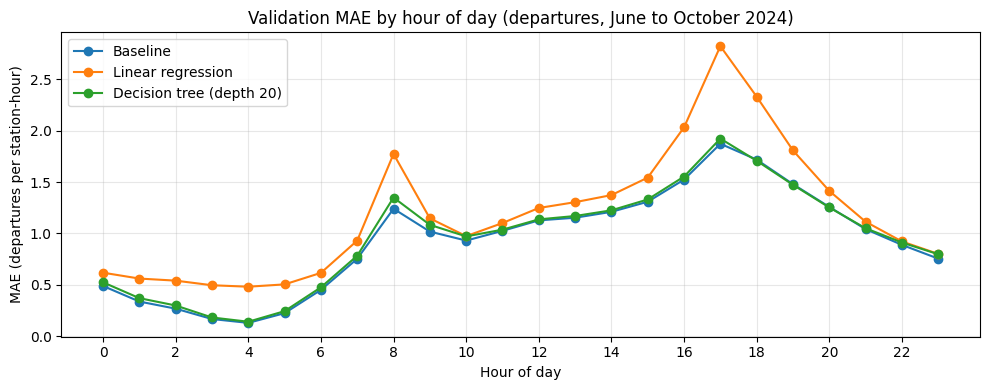

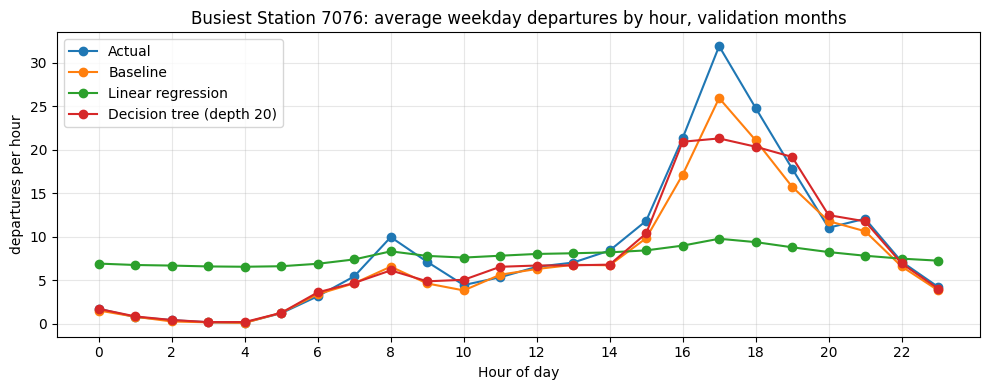

In [13]:
# table of scores
comparison = pd.DataFrame(scores, index=["MAE", "RMSE"]).T
baseline_mae = comparison.loc["Baseline", "MAE"]
comparison["change vs baseline MAE"] = (comparison["MAE"] / baseline_mae - 1) * 100
comparison = comparison.round(4)
print(comparison.to_string())

# which column in val_results belongs to which model name
model_columns = {"Baseline": "baseline", "Linear regression": "linear", tree_name: "tree"}

# MAE by hour of day on validation, one line per model
by_hour = pd.DataFrame(index=range(24))
for name, column in model_columns.items():
    abs_error = (val_results[column] - val_results["actual"]).abs()
    by_hour[name] = abs_error.groupby(val["hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o")
ax.set_title(f"Validation MAE by hour of day ({TARGET}, June to October 2024)")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"MAE ({TARGET} per station-hour)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# the busiest station in training: average weekday profile, actual vs predicted
busiest_station = train.groupby("station_id")[TARGET].sum().idxmax()
is_busiest_weekday = (val["station_id"] == busiest_station) & (val["weekend_or_holiday"] == 0)

profile = pd.DataFrame(index=range(24))
profile["Actual"] = val_results.loc[is_busiest_weekday, "actual"].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()
for name, column in model_columns.items():
    profile[name] = val_results.loc[is_busiest_weekday, column].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, marker="o")
ax.set_title(f"Busiest Station {busiest_station}: average weekday {TARGET} by hour, validation months")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"{TARGET} per hour")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# keep this target's validation results and chosen depth for Part 4
saved[TARGET] = {"val": val_results.copy(), "columns": dict(model_columns),
                 "tree_name": tree_name, "best_depth": best_depth}
print("Saved results for:", list(saved.keys()))


Saved results for: ['departures']


**E. Summary**

For the Regression Task (Departures), we created the baseline model (using simple averages), a linear regression model, and a decision tree model with hyperparameter-tuning of its depth from 6-20.

Based on the results above, neither model beat the baseline on the Validation set. The Decision tree with depth 20 comes close to the baseline's prediction but failed to find the peak any better than the baseline does (see the graph of the busiest station's average weekday departures above).

One interesting thing to note is that the Linear Regression model did very poorly on the busiest station. Its predictions are nearly flat, which  indicates that it was unable to find the true shape of the busy stations.

**F. Final Model**

The simplest model (baseline model) was actually the most accurate. However, between our 2 ML models, the Decision tree is close to the baseline and we will select this for the final test and for analysis of possible improvements.

Compared to the other 2 models, the Decision tree is the most complex at the selected depth of 20. We will re-train this model in the Part 4 on the Training+Validation set and use the Test set to evaluate it.

#### 2. **Regression: Arrivals**

The Regression Models for Arrivals are the same as those for Departures but with a different target.

In [15]:
# Choose the target
TARGET = "arrivals"

val_results = pd.DataFrame()
val_results["station_id"] = val["station_id"]
val_results["hour_ts"] = val["hour_ts"]
val_results["actual"] = val[TARGET]
scores = {}
train_mae = {}

**A. Baseline Model**

In [16]:
val_results["baseline"] = baseline_predict(train, val)
scores["Baseline"] = evaluate(val_results["actual"], val_results["baseline"])
train_mae["Baseline"] = mean_absolute_error(train[TARGET], baseline_predict(train, train))
print("Baseline on validation: MAE = %.4f, RMSE = %.4f" % scores["Baseline"])

Baseline on validation: MAE = 0.9186, RMSE = 1.8204


**B. Linear Regression**

In [17]:
# one-hot encode the categorical columns, pass the numeric columns through unchanged
encoder = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("numeric", "passthrough", NUMERIC),
])

# fit the encoder and the model on the training rows
X_train = encoder.fit_transform(train[CATEGORICAL + NUMERIC])
y_train = train[TARGET]
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# predict the validation rows
X_val = encoder.transform(val[CATEGORICAL + NUMERIC])
linear_raw = linear_model.predict(X_val)

share_negative = (linear_raw < 0).mean()
print(f"Percentage of validation predictions below zero: {share_negative:.1%}  (set to 0 before scoring)")

val_results["linear"] = np.clip(linear_raw, 0, None)
scores["Linear regression"] = evaluate(val_results["actual"], val_results["linear"])
print("Linear regression on validation: MAE = %.4f, RMSE = %.4f" % scores["Linear regression"])

# the coefficients of the numeric features are easy to read: change in the target per one unit of the feature
numeric_coefficients = pd.Series(linear_model.coef_[-len(NUMERIC):], index=NUMERIC)
print("\nCoefficients of the numeric features:")
print(numeric_coefficients.round(4).to_string())

Percentage of validation predictions below zero: 20.1%  (set to 0 before scoring)
Linear regression on validation: MAE = 1.1868, RMSE = 2.3374

Coefficients of the numeric features:
year                  0.0134
weekend_or_holiday   -0.3965
temp_c                0.0377
precip_mm            -0.1030
prec_mm_prev_hr      -0.0691
new_station          -0.4204


**C. Decision Tree**

In [18]:
TREE_FEATURES = ["station_avg", "hour_of_day", "day_of_week", "month"] + NUMERIC

train_tree = train[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
train_tree["station_avg"] = station_average(train, train)
train_tree = train_tree[TREE_FEATURES]

val_tree = val[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
val_tree["station_avg"] = station_average(train, val)
val_tree = val_tree[TREE_FEATURES]

# HYPERPARAMETER TUNING --- try several depths
depths = [6, 9, 12, 15, 20]
depth_rows = []
tree_predictions = {}
for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=100)
    tree.fit(train_tree, train[TARGET])
    prediction = tree.predict(val_tree)
    tree_predictions[depth] = prediction

    train_mae = mean_absolute_error(train[TARGET], tree.predict(train_tree))
    val_mae, val_rmse = evaluate(val[TARGET], prediction)
    depth_rows.append({"max_depth": depth, "train MAE": train_mae, "val MAE": val_mae, "val RMSE": val_rmse})

depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(4).to_string(index=False))

# keep the depth with the lowest validation MAE
best_row = depth_table.loc[depth_table["val MAE"].idxmin()]
best_depth = int(best_row["max_depth"])
print(f"\nChosen depth: {best_depth}")

val_results["tree"] = tree_predictions[best_depth]
tree_name = f"Decision tree (depth {best_depth})"
scores[tree_name] = evaluate(val_results["actual"], val_results["tree"])
print(tree_name + " on validation: MAE = %.4f, RMSE = %.4f" % scores[tree_name])

# which features the chosen tree uses most
best_tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=100)
best_tree.fit(train_tree, train[TARGET])
importance = pd.Series(best_tree.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False)
print("\nFeature importance:")
print(importance.round(3).to_string())

 max_depth  train MAE  val MAE  val RMSE
         6     1.0006   1.0491    2.1779
         9     0.9420   1.0033    2.0203
        12     0.9027   0.9737    1.9578
        15     0.8719   0.9581    1.9064
        20     0.8451   0.9457    1.8743

Chosen depth: 20
Decision tree (depth 20) on validation: MAE = 0.9457, RMSE = 1.8743

Feature importance:
station_avg           0.560
hour_of_day           0.339
day_of_week           0.035
temp_c                0.027
weekend_or_holiday    0.026
precip_mm             0.007
month                 0.005
prec_mm_prev_hr       0.001
year                  0.001
new_station           0.000


**D. Comparison of Models and Selection**

                             MAE    RMSE  change vs baseline MAE
Baseline                  0.9186  1.8204                  0.0000
Linear regression         1.1868  2.3374                 29.2088
Decision tree (depth 20)  0.9457  1.8743                  2.9552


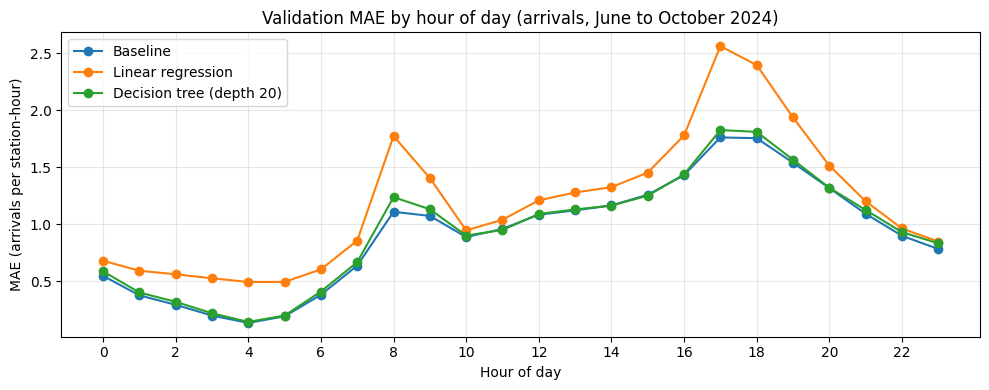

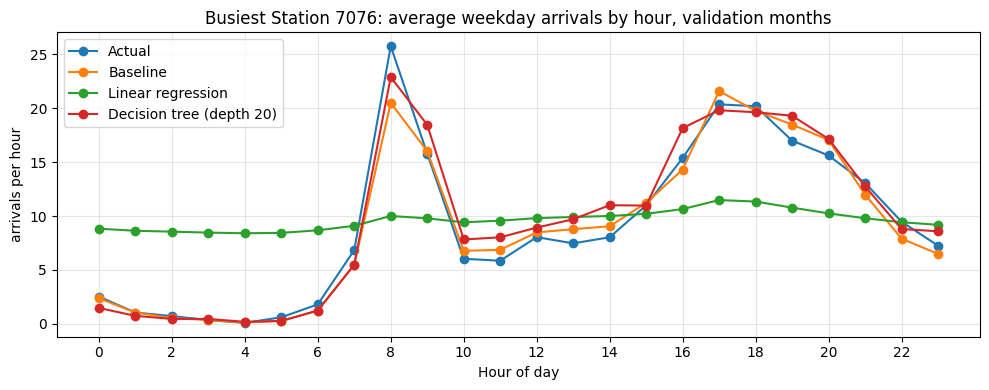

In [19]:
# table of scores
comparison = pd.DataFrame(scores, index=["MAE", "RMSE"]).T
baseline_mae = comparison.loc["Baseline", "MAE"]
comparison["change vs baseline MAE"] = (comparison["MAE"] / baseline_mae - 1) * 100
comparison = comparison.round(4)
print(comparison.to_string())

# which column in val_results belongs to which model name
model_columns = {"Baseline": "baseline", "Linear regression": "linear", tree_name: "tree"}

# MAE by hour of day on validation, one line per model
by_hour = pd.DataFrame(index=range(24))
for name, column in model_columns.items():
    abs_error = (val_results[column] - val_results["actual"]).abs()
    by_hour[name] = abs_error.groupby(val["hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o")
ax.set_title(f"Validation MAE by hour of day ({TARGET}, June to October 2024)")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"MAE ({TARGET} per station-hour)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# the busiest station in training: average weekday profile, actual vs predicted
busiest_station = train.groupby("station_id")[TARGET].sum().idxmax()
is_busiest_weekday = (val["station_id"] == busiest_station) & (val["weekend_or_holiday"] == 0)

profile = pd.DataFrame(index=range(24))
profile["Actual"] = val_results.loc[is_busiest_weekday, "actual"].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()
for name, column in model_columns.items():
    profile[name] = val_results.loc[is_busiest_weekday, column].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, marker="o")
ax.set_title(f"Busiest Station {busiest_station}: average weekday {TARGET} by hour, validation months")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"{TARGET} per hour")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# keep this target's validation results and chosen depth for Part 4
saved[TARGET] = {"val": val_results.copy(), "columns": dict(model_columns),
                 "tree_name": tree_name, "best_depth": best_depth}
print("Saved results for:", list(saved.keys()))


Saved results for: ['departures', 'arrivals']


**E. Summary**

For the Regression Task (Arrivals), we created the baseline model (using simple averages), a linear regression model, and a decision tree model with hyperparameter-tuning of its depth from 6-20. The code is mostly identical to the Regression Task for Departures but with a different TARGET.

Based on the results above, neither model beat the baseline on the Validation set. The Decision tree with depth 20 comes close to the baseline's prediction and the graph of the busiest station for arrivals shows that its curve is very similar to both the baseline and actual value for arrivals.

The Linear Regression model still did very poorly on the busiest station. As with the Regression Task for Departures, its predictions are nearly flat, which  indicates that it was unable to find the true shape of the busy stations.

**F. Final Model**

The results being the same as for the Departures, we will also select the Decision tree as our final model for the Regression task for Arrivals.

### Classification Model (Classify stations by Demand)

#### 1. **Classification: Low/Medium/High Demand**

Code for the logistic regression and kNN models with performance metrics included:

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load preprocessed classification table
cls_data = pd.read_parquet(f"{PROCESSED}/classification_station_month_may_oct.parquet")

FEATURES = ["monthly_volume", "was_flagged_new", "first_year", "first_month"]
DEMAND_LABELS = ["Low", "Medium", "High"]

train_df = cls_data[cls_data["split"] == "train"]
val_df = cls_data[cls_data["split"] == "val"]
test_df = cls_data[cls_data["split"] == "test"]

X_train_raw, y_train = train_df[FEATURES], train_df["target"]
X_val_raw, y_val = val_df[FEATURES], val_df["target"]
X_test_raw, y_test = test_df[FEATURES], test_df["target"]

# -------------------------------------------------------------
# STEP 1: TRAIN & COMPARE ON VALIDATION SET
# -------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

log_reg = LogisticRegression(solver="lbfgs", max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
knn.fit(X_train_scaled, y_train)

for name, model in [("Logistic Regression", log_reg), ("k-Nearest Neighbors (k=5)", knn)]:
    print(f"\n==================== {name.upper()} (TRAIN vs. VAL) ====================")
    for X_split, y_split, split_name in [(X_train_scaled, y_train, "Train"), (X_val_scaled, y_val, "Validation")]:
        preds = model.predict(X_split)
        print(f"--- {split_name} Accuracy: {accuracy_score(y_split, preds):.4f} ---")
        print(classification_report(y_split, preds, target_names=DEMAND_LABELS, zero_division=0))

# -------------------------------------------------------------
# STEP 2: RETRAIN ON TRAIN + VALIDATION & EVALUATE ON TEST SET
# -------------------------------------------------------------
print("\n==================== FINAL TEST EVALUATION (TRAIN+VAL -> TEST) ====================")
X_trainval_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
y_trainval = pd.concat([y_train, y_val], ignore_index=True)

final_scaler = StandardScaler()
X_trainval_scaled = final_scaler.fit_transform(X_trainval_raw)
X_test_scaled = final_scaler.transform(X_test_raw)

final_log_reg = LogisticRegression(solver="lbfgs", max_iter=1000)
final_log_reg.fit(X_trainval_scaled, y_trainval)

final_knn = KNeighborsClassifier(n_neighbors=5, weights="uniform")
final_knn.fit(X_trainval_scaled, y_trainval)

for name, model in [("Logistic Regression", final_log_reg), ("k-Nearest Neighbors (k=5)", final_knn)]:
    test_preds = model.predict(X_test_scaled)
    print(f"\n--- Final Test Set: {name} ---")
    print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f}")
    print(classification_report(y_test, test_preds, target_names=DEMAND_LABELS, zero_division=0))



==================== LOGISTIC REGRESSION (TRAIN vs. VAL) ====================
--- Train Accuracy: 0.9171 ---
              precision    recall  f1-score   support

         Low       0.92      0.95      0.94      1399
      Medium       0.89      0.87      0.88      1740
        High       0.94      0.93      0.94      1817

    accuracy                           0.92      4956
   macro avg       0.92      0.92      0.92      4956
weighted avg       0.92      0.92      0.92      4956

--- Validation Accuracy: 0.8765 ---
              precision    recall  f1-score   support

         Low       0.95      0.90      0.92      1354
      Medium       0.84      0.77      0.81      1316
        High       0.84      0.96      0.90      1323

    accuracy                           0.88      3993
   macro avg       0.88      0.88      0.88      3993
weighted avg       0.88      0.88      0.88      3993


==================== K-NEAREST NEIGHBORS (K=5) (TRAIN vs. VAL) ====================
--- Tra

As we can see from the metrics provided above, both models do a good job at classifying the stations as low, medium and high. Both models porvide good accuracy, precision, recall and f1-score for each of our targets. Even though both models predict our targets well, we decided to move forward with the logistic regression model.

We chose this model because even though the difference in the performance metrics is very similar to that of the kNN model, we will not need to to standardization on our logistic regression model like we would need to for the kNN model. Standardizing the data can lead to a more complex model, which can result in overfitting our data, leading to a model that is too accurate as it can memorize the training data.

## Part 4: Model Evaluation & Analytical Depth

### Regression

Re-train the selected model (Decision tree, depth of 20) on Training+Validation (all of 2023-2024) and evaluate on Test (2025):

In [22]:
fit_data = pd.concat([train, val], ignore_index=True)   # all of May to October 2023 and 2024

for TARGET in ["departures", "arrivals"]:
    res = saved[TARGET]

    test_results = pd.DataFrame()
    test_results["station_id"] = test["station_id"]
    test_results["hour_ts"] = test["hour_ts"]
    test_results["actual"] = test[TARGET]

    # baseline recomputed on training + validation, for the comparison
    test_results["baseline"] = baseline_predict(fit_data, test)

    # final model: decision tree with the depth chosen on validation
    fit_tree = fit_data[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
    fit_tree["station_avg"] = station_average(fit_data, fit_data)
    test_tree = test[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
    test_tree["station_avg"] = station_average(fit_data, test)
    final_model = DecisionTreeRegressor(max_depth=res["best_depth"], min_samples_leaf=100)
    final_model.fit(fit_tree[TREE_FEATURES], fit_data[TARGET])
    test_results["final"] = final_model.predict(test_tree[TREE_FEATURES])

    rows = []
    for name, column in [("Baseline", "baseline"), (res["tree_name"], "final")]:
        mae, rmse = evaluate(test_results["actual"], test_results[column])
        rows.append({"model": name, "test MAE": mae, "test RMSE": rmse,
                     "test R2": r2_score(test_results["actual"], test_results[column])})
    test_table = pd.DataFrame(rows).set_index("model")
    test_table["test MAE vs baseline (%)"] = (test_table["test MAE"] / test_table.loc["Baseline", "test MAE"] - 1) * 100

    print(f"\n===== {TARGET.upper()}: test months (May to October 2025), "
          f"{len(test):,} station-hours, {test['station_id'].nunique()} stations =====")
    print(test_table.round(4).to_string())
    res["test"] = test_results


===== DEPARTURES: test months (May to October 2025), 4,220,184 station-hours, 1032 stations =====
                          test MAE  test RMSE  test R2  test MAE vs baseline (%)
model                                                                           
Baseline                    1.0527     2.4264   0.4350                    0.0000
Decision tree (depth 20)    1.0654     2.4356   0.4307                    1.1995

===== ARRIVALS: test months (May to October 2025), 4,220,184 station-hours, 1032 stations =====
                          test MAE  test RMSE  test R2  test MAE vs baseline (%)
model                                                                           
Baseline                    1.0397     2.4416   0.4826                      0.00
Decision tree (depth 20)    1.0301     2.4368   0.4846                     -0.92



===== DEPARTURES: validation months (June to October 2024) =====
                            MAE   RMSE     R2  mean error  mean error, hours with departures/arrivals > 10
model                                                                                                     
Baseline                  0.932  1.795  0.571      -0.181                                           -6.342
Linear regression         1.186  2.167  0.375       0.014                                           -9.302
Decision tree (depth 20)  0.958  1.833  0.553      -0.122                                           -6.405

Validation MAE by month:
       Baseline  Linear regression  Decision tree (depth 20)
month                                                       
6         0.872              1.120                     0.906
7         0.957              1.221                     0.986
8         0.952              1.234                     0.985
9         0.981              1.268                     1.007
10     

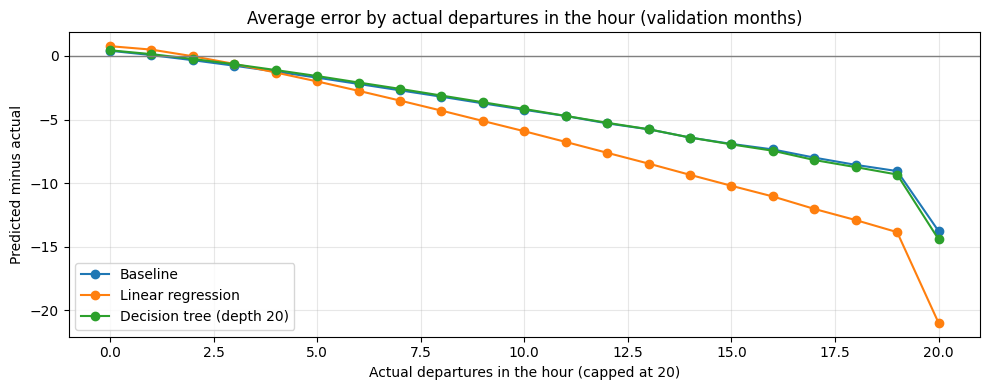


===== ARRIVALS: validation months (June to October 2024) =====
                            MAE   RMSE     R2  mean error  mean error, hours with departures/arrivals > 10
model                                                                                                     
Baseline                  0.919  1.820  0.606      -0.181                                           -6.207
Linear regression         1.187  2.337  0.350       0.015                                           -9.493
Decision tree (depth 20)  0.946  1.874  0.582      -0.123                                           -6.239

Validation MAE by month:
       Baseline  Linear regression  Decision tree (depth 20)
month                                                       
6         0.863              1.121                     0.895
7         0.939              1.223                     0.974
8         0.937              1.237                     0.974
9         0.964              1.267                     0.990
10       

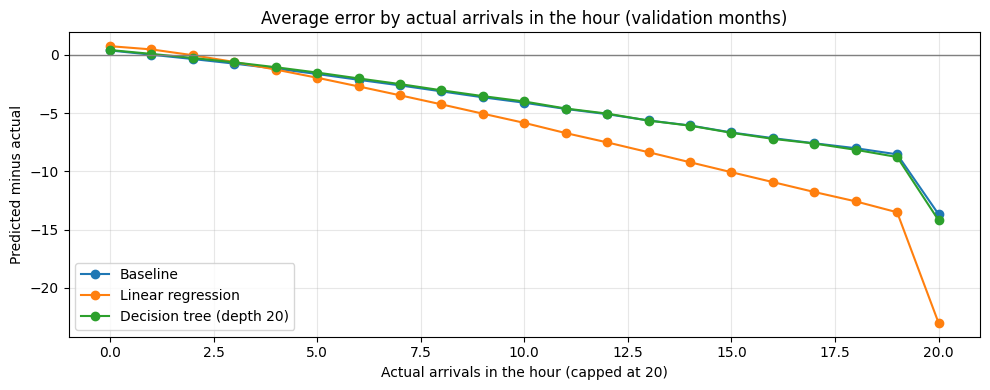

In [23]:
for target in ["departures", "arrivals"]:
    res = saved[target]
    v = res["val"]
    actual = v["actual"]
    busy = actual >= 10

    # one row of scores per model
    rows = []
    for name, column in res["columns"].items():
        error = v[column] - actual
        mae, rmse = evaluate(actual, v[column])
        rows.append({"model": name,
                     "MAE": mae,
                     "RMSE": rmse,
                     "R2": r2_score(actual, v[column]),
                     "mean error": error.mean(),
                     "mean error, hours with departures/arrivals > 10": error[busy].mean()})
    print(f"\n===== {target.upper()}: validation months (June to October 2024) =====")
    print(pd.DataFrame(rows).set_index("model").round(3).to_string())


    # MAE by month, one column per model
    by_month = pd.DataFrame()
    for name, column in res["columns"].items():
        abs_error = (v[column] - actual).abs()
        by_month[name] = abs_error.groupby(v["hour_ts"].dt.month).mean()
    by_month.index.name = "month"
    print("\nValidation MAE by month:")
    print(by_month.round(3).to_string())

    # residual plot: average error at each actual value (20 and above grouped together)
    actual_group = actual.clip(upper=20)
    fig, ax = plt.subplots(figsize=(10, 4))
    for name, column in res["columns"].items():
        error = v[column] - actual
        mean_error = error.groupby(actual_group).mean()
        ax.plot(mean_error.index, mean_error.values, marker="o", label=name)
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_title(f"Average error by actual {target} in the hour (validation months)")
    ax.set_xlabel(f"Actual {target} in the hour (capped at 20)")
    ax.set_ylabel("Predicted minus actual")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

#### **1. Regression: Departures**

The following analysis is based on the results above:

1. **Interpretation:** The MAE of ~0.93 - 0.96 means that predictions (baseline and decision tree) are wrong by ~1 departure per station per hour on average. The average station-hour has only ~1.4 departures so this result shows that the error is actually quite large in comparison. R² values for baseline and decision tree are around 0.55-0.57 and for linear regression, it is ~0.38. This means that at best, the baseline and decision tree models explain just over half of the variation in the bike share ridership data, and linear regression can explain less than half.
2. **Training vs validation vs test:** For the decision tree, the training MAE is 0.86 and the validation MAE is 0.96 at depth 20. At depth 6 the values were 0.99 for training and 1.04 for validation. On the Test set, the final decision tree (retrained on Training + Validation) has an MAE of 1.07.
3. **Bias vs variance:** As seen in the results, the linear regression model has high bias and is too simple to explain the data. It is an additive model, which gives every station the same hourly shape whether it is a busy station or a quiet one at that hour. That's why the graphs show that its predictions plot nearly a flat line even for the busiest stations (both departures and arrivals). The decision tree does better because it can capture more complex patterns, so it has lower bias. The cost is higher variance as the depth increases: the gap between training and validation MAE grows from ~0.05 at depth 6 to ~0.10 at depth 20. The validation MAE was still improving at depth 20, so we did not see the tree getting worse from overfitting, but 20 was the deepest value we tried.
4. **Error analysis:** All models predicted too low on busy hours and could not predict the peak. On hours with 10 or more departures, the baseline and the decision tree are too low by ~6 departures and linear regression by ~9 (see the residual plot). These are the hours that matter most for growth planning. Also, ~20% of the linear regression predictions were below zero before we set them to 0.
5. **Robustness:** The validation MAE is stable from month to month: between 0.87 and 0.98 for the baseline and between 0.91 and 1.01 for the decision tree, and the order of the models is the same in every month (results differ slightly between runs but remain in the same ranges).

**Final model on the Test set (May to October 2025)**

| Model (trained on Training + Validation) | MAE | RMSE | R² |
|--|--|--|--|
| Baseline | 1.05 | 2.43 | 0.44 |
| Decision tree (depth 20) | 1.07 | 2.44 | 0.43 |

6. The decision tree is ~1.2% behind the baseline on the Test set, so our success criterion from 1.2 (lower Test MAE than the baseline) is not met for departures. Both models are worse on the Test set than on the Validation set (MAE 1.05 to 1.07 against 0.93 to 0.96). The Test set is a later year with more stations (1,032 against 863 in validation), and stations with no history get an overall average.

#### **2. Regression: Arrivals**

The following analysis is based on the results above:

1. **Interpretation:** The MAE of ~0.92 - 0.95 means that predictions (baseline and decision tree) are wrong by ~1 arrival per station per hour on average. Similar to departures, average station-hour has only ~1.4 arrivals so this result shows that the error is actually quite large in comparison. R² values for baseline and decision tree are around 0.58-0.61 and for linear regression, it is ~0.35. This means that at best, the baseline and decision tree models explain around 60% of the variation in the bike share ridership data which is slightly better than the result for departures regression task, and linear regression can explain much less than half.
2. **Training vs validation vs test:** For the decision tree, the training MAE is 0.85 and the validation MAE is 0.95 at depth 20. At depth 6 the values were 1.00 for training and 1.05 for validation. On the Test set, the final decision tree (retrained on Training + Validation) has an MAE of 1.03.
3. **Bias vs variance:** The results are the same as for departures. The linear regression model has high bias and is too simple to explain the data, since it gives every station the same hourly shape. The decision tree does better because it can capture more complex patterns, so it has lower bias. The cost is higher variance as the depth increases: the gap between training and validation MAE grows from ~0.05 at depth 6 to ~0.10 at depth 20. The validation MAE was still improving at depth 20, so we did not see the tree getting worse from overfitting, but 20 was the deepest value we tried.
4. **Error analysis:** All models predicted too low on busy hours and could not predict the peak. On hours with 10 or more arrivals, the baseline and the decision tree are too low by ~6 arrivals and linear regression by ~9.5 (see the residual plot). These are the hours that matter most for growth planning. Also, ~20% of the linear regression predictions were below zero before we set them to 0.
5. **Robustness:** The validation MAE is stable from month to month: between 0.86 and 0.96 for the baseline and between 0.89 and 0.99 for the decision tree, and the order of the models is the same in every month (results differ slightly between runs but remain in the same ranges).

**Final model on the Test set (May to October 2025)**

| Model (trained on Training + Validation) | MAE | RMSE | R² |
|--|--|--|--|
| Baseline | 1.04 | 2.44 | 0.48 |
| Decision tree (depth 20) | 1.03 | 2.44 | 0.48 |

6. The decision tree is ~0.9% better than the baseline on the Test set, so our success criterion from 1.2 (lower Test MAE than the baseline) is met for arrivals, but only by a small margin. Both models are worse on the Test set than on the Validation set (MAE 1.03 to 1.04 against 0.92 to 0.95). The Test set is a later year with more stations (1,032 against 863 in validation), and stations with no history get an overall average.

### Classification

Code to generate confusion matrices:

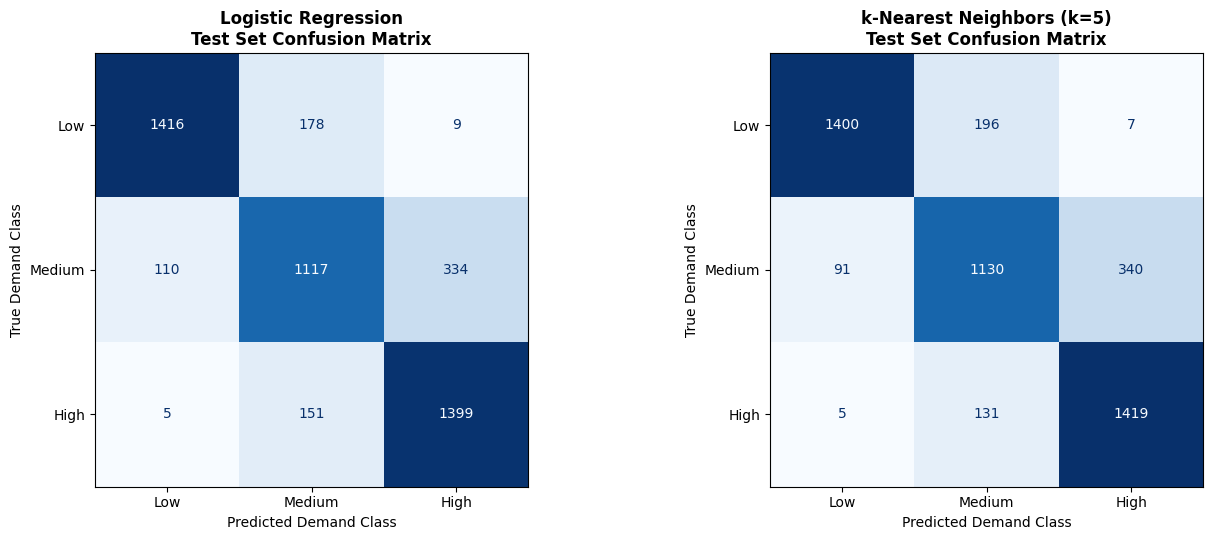

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

models = [
    ("Logistic Regression", final_log_reg),
    ("k-Nearest Neighbors (k=5)", final_knn)
]

# -------------------------------------------------------------
# 1. SIDE-BY-SIDE CONFUSION MATRICES (TEST SET)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    preds = model.predict(X_test_scaled)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        preds,
        display_labels=DEMAND_LABELS,
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"{name}\nTest Set Confusion Matrix", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Demand Class")
    ax.set_ylabel("True Demand Class")

plt.tight_layout()
plt.show()




Can see that our models do a good job at correctly predicting the station type (low, medium and high).

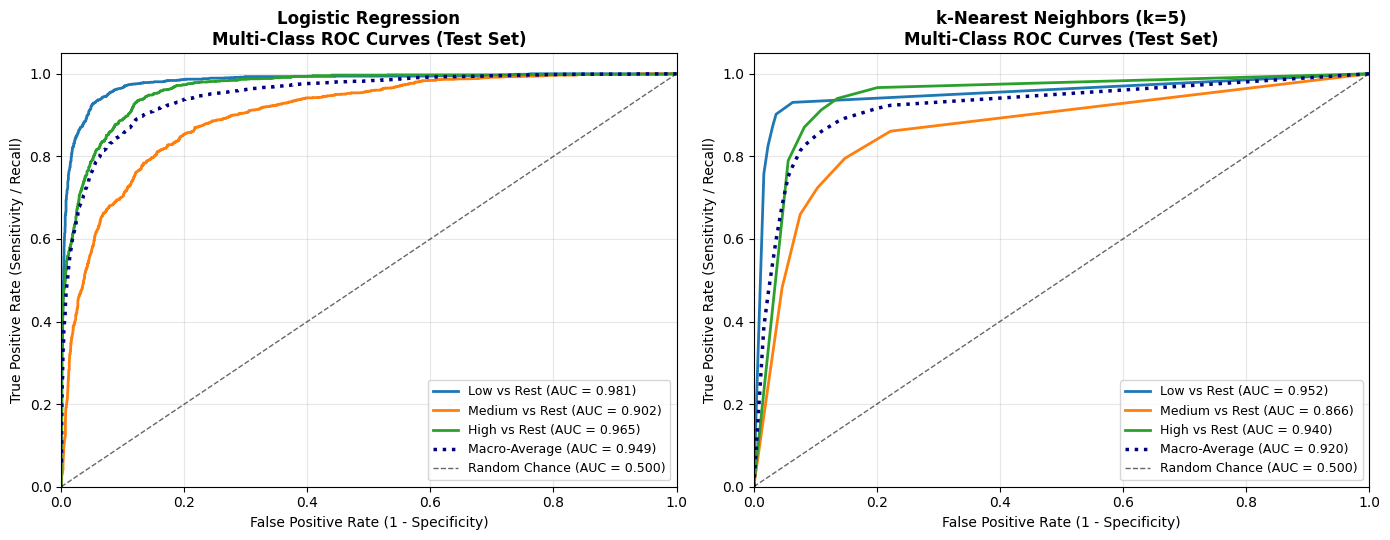

In [25]:
# -------------------------------------------------------------
# 2. MULTI-CLASS ROC CURVES (ONE-VS-REST ON TEST SET)
# -------------------------------------------------------------
# Binarize true labels into [0, 1, 2] columns for One-vs-Rest ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = len(DEMAND_LABELS)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (name, model) in zip(axes, models):
    y_score = model.predict_proba(X_test_scaled)

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        ax.plot(
            fpr[i], tpr[i],
            color=colors[i],
            lw=2,
            label=f"{DEMAND_LABELS[i]} vs Rest (AUC = {roc_auc[i]:.3f})"
        )

    # Compute Macro-Average ROC curve & AUC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)

    ax.plot(
        all_fpr, mean_tpr,
        color="navy", linestyle=":", linewidth=2.5,
        label=f"Macro-Average (AUC = {macro_auc:.3f})"
    )

    # Diagonal random-guess reference line
    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Random Chance (AUC = 0.500)")

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate (1 - Specificity)")
    ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
    ax.set_title(f"{name}\nMulti-Class ROC Curves (Test Set)", fontsize=12, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

From the plots, we can see that the logistic regression model is a smoother curve, and its values are higher than that for the kNN model. This is another reason we decided to move foreard with the logistic regression model, as a higher AUC for the ROC curve tells us it is better at classifying our stations.

## Part 5: Analytical Reflection (1 Page Required-Very important)

1. **Does the final model generalize well?**

It only partly generalizes well for the regression tasks. The final model selected (Decision tree) performs similarly to the Baseline model (slightly worse for departures and slightly better for arrivals). This means that it hasn't learned much more than each station's usual pattern and simply getting averages is good enough given this dataset.
For the classification task, the results were acceptable. Test accuracy is ~ 0.83 for both logistic regression and kNN, which is a little lower than on the Validation set (~ 0.88).

2. **Structural weaknesses:**

The linear regression model has high bias and is too simple for this dataset. It gives every station the same hourly shape, so it cannot explain busy vs quiet stations at the same time. The decision tree only knows each station by its overall average, so it has to rebuild each station's hourly pattern one split at a time. All regression models predicted too low on the busiest hours, which are the hours that matter most for growth planning. Stations that first appear after the training months have no history and get an overall average. Also, our training data has only one full season (2023) plus May 2024, so the models see very little of the growth from year to year.

3. **Real-world deployment risks:**

For the classification task, we think that precision is more important than recall. It costs more to build a station or add docks where they are not needed than it would to miss a high-demand area. Another risk is that the bike share network keeps growing, so a model trained on past years will always meet new stations that it knows nothing about. We were not able to do the business check from 1.2 (comparing the stations classified as High in 2024 with the stations added in 2025). We will do this in the next milestone, so we cannot say yet whether our outputs would have pointed to the right places.

4. **Was augmentation beneficial?**

We did not use data generation or augmentation. The zero-trip hours are actual observations, and the demand classes are close to equal in size.

5. **Future improvements for the regression models:**

    - Tune the decision tree more widely. The validation error was still going down at depth 20, so we will try depths above 20 and different minimum leaf sizes.
    - Add a feature that captures growth, since `year` had almost no effect in either model.
    - Report the errors separately for quiet, medium and busy stations, since the overall MAE is dominated by quiet hours.
    - Look for additional datasets that may help add useful features to the models.